In [68]:
import os
import json
import pickle
import random
import math

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import cv2

from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_distances
from sklearn.preprocessing import StandardScaler

import ot

import torch
import torch.nn.functional as F
from diffusers import AutoencoderKL

from joblib import Parallel, delayed
from tqdm import tqdm
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt


In [36]:
DATASET_DIR = "abstrait-v4"
TARGET_SIZE = 300

In [37]:
def pad_image_symmetric(img_path, target_size=TARGET_SIZE):
    
    img = cv2.imread(img_path)
    
    if img is None:
        raise ValueError(f"Impossible de charger l'image : {img_path}")
        
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    h, w = img.shape[:2]
    max_dim = max(h, w)
    
    if max_dim != target_size:
        # print(f"{img_path} ({w}x{h})")
        scale = target_size / max_dim
        new_w = int(w * scale)
        new_h = int(h * scale)
        
        interpolation = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC
        img = cv2.resize(img, (new_w, new_h), interpolation=interpolation)
        
        h, w = img.shape[:2]
        
    delta_w = target_size - w
    delta_h = target_size - h
    
    top = delta_h // 2
    bottom = delta_h - top
    left = delta_w // 2
    right = delta_w - left
    
    padded_img = cv2.copyMakeBorder(
        img, 
        top, bottom, left, right, 
        cv2.BORDER_REFLECT
    )
    
    return padded_img

In [22]:
images = [(img, pad_image_symmetric(os.path.join(DATASET_DIR, img), TARGET_SIZE)) for img in os.listdir(DATASET_DIR) if img.lower().endswith(('.jpg', '.jpeg'))]

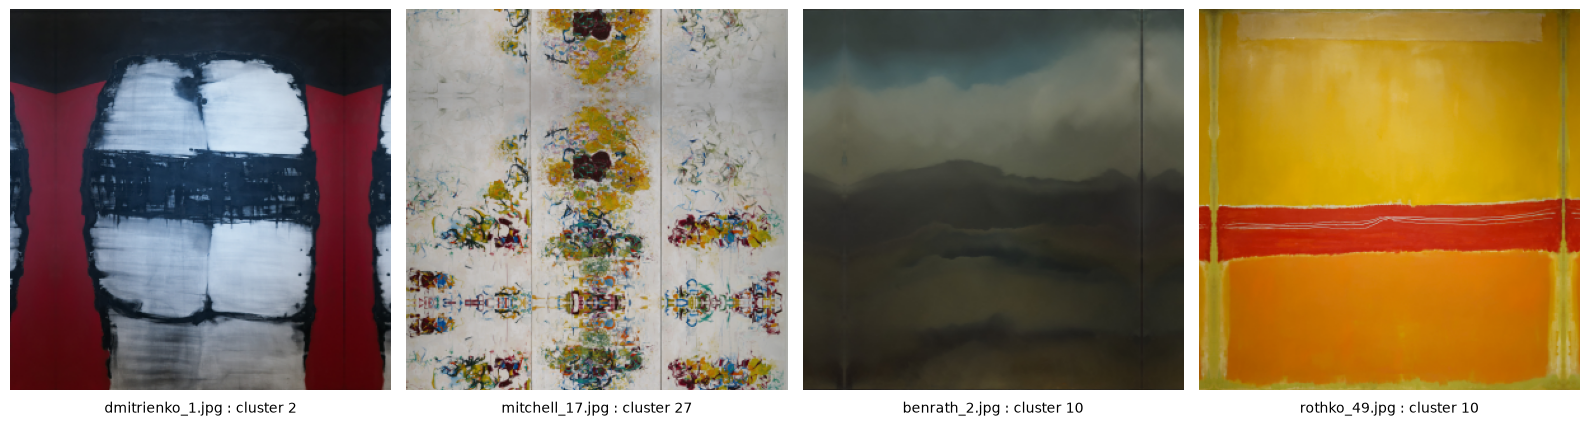

In [72]:
selected_img = random.sample(images, 4)

df = pd.read_csv("classification_finale_oeuvres.csv")

# 3. Filtrage et extraction sous forme de dictionnaire {nom_fichier: cluster_id}
df_selected = df[df["Nom_Fichier"].isin([x[0] for x in selected_img])]
clusters = dict(zip(df_selected["Nom_Fichier"], df_selected["Cluster_ID"]))


fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for idx, (filename, img) in enumerate(selected_img):
    # Normalisation [0, 1] si l'image est encore en entiers [0, 255]
    display_img = img / 255.0 if img.max() > 1.0 else img

    axes[idx].imshow(display_img)
    axes[idx].axis("off")
    # Positionnement du titre sous l'image avec 'y' négatif
    cluster_id = clusters.get(filename, "Introuvable")
    axes[idx].set_title(f"{filename} : cluster {cluster_id}", y=-0.08, fontsize=10, wrap=True)

plt.tight_layout()
plt.show()

In [73]:
device = "cuda" if torch.cuda.is_available() else "cpu"
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device)
vae.eval()

def encode_painting(img_array):
    """Encode une image RGB (H, W, 3) en un nuage de 1444 patchs latents de dimension 4"""
    img = np.array(img_array, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).to(device)
    tensor = F.interpolate(tensor, size=(304, 304), mode="bilinear", align_corners=False)
    tensor = (tensor * 2.0) - 1.0
    
    with torch.no_grad():
        z = vae.encode(tensor).latent_dist.mode() # (1, 4, 38, 38)
    
    z_cloud = z.squeeze(0).permute(1, 2, 0).reshape(-1, 4).cpu().numpy()
    return z_cloud

def decode_latent_cloud(z_cloud):
    """Reconstruit l'image RGB à partir d'un nuage latent (1444, 4)"""
    z_tensor = torch.from_numpy(z_cloud).float().to(device)
    z_tensor = z_tensor.reshape(38, 38, 4).permute(2, 0, 1).unsqueeze(0)
    
    with torch.no_grad():
        decoded = vae.decode(z_tensor).sample
    decoded = (decoded / 2.0 + 0.5).clamp(0, 1)
    return decoded.squeeze(0).permute(1, 2, 0).cpu().numpy()

grid_y, grid_x = np.meshgrid(np.linspace(0, 1, 38), np.linspace(0, 1, 38), indexing='ij')
spatial_coords = np.stack([grid_x.ravel(), grid_y.ravel()], axis=1) # (1444, 2)
M_spatial = ot.dist(spatial_coords, spatial_coords, metric='sqeuclidean')

def compute_latent_ot(zA, zB, alpha=10.0):
    """
    Calcule la distance de Wasserstein W2 et le plan de transport exact entre deux tableaux
    alpha contrôle l'importance de la structure spatiale par rapport au style pur
    """
    N = zA.shape[0]
    a, b = np.ones(N) / N, np.ones(N) / N # Poids uniformes sur les 1444 patchs
    
    # Matrice de coût combinant sémantique (latent) et géométrie (spatial)
    M_latent = ot.dist(zA, zB, metric='sqeuclidean')
    M_total = M_latent + alpha * M_spatial
    
    G = ot.emd(a, b, M_total)
    
    w2_dist = np.sqrt(np.sum(G * M_total))
    
    zB_transported_to_A = N * (G @ zB)
    
    return w2_dist, zB_transported_to_A

/Users/arthurevain/Documents/Code/abstract_art_classification/.venv/lib/python3.14/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


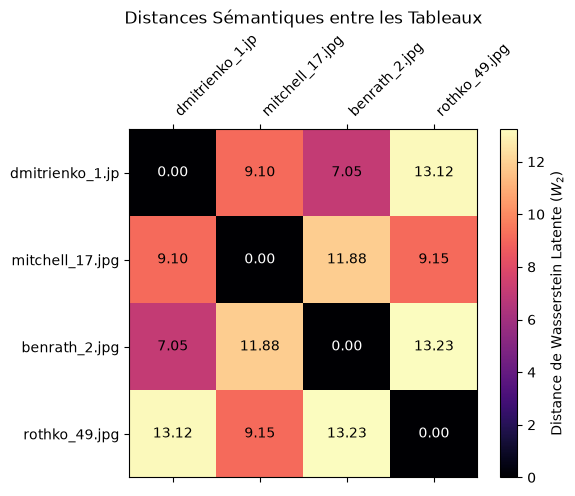

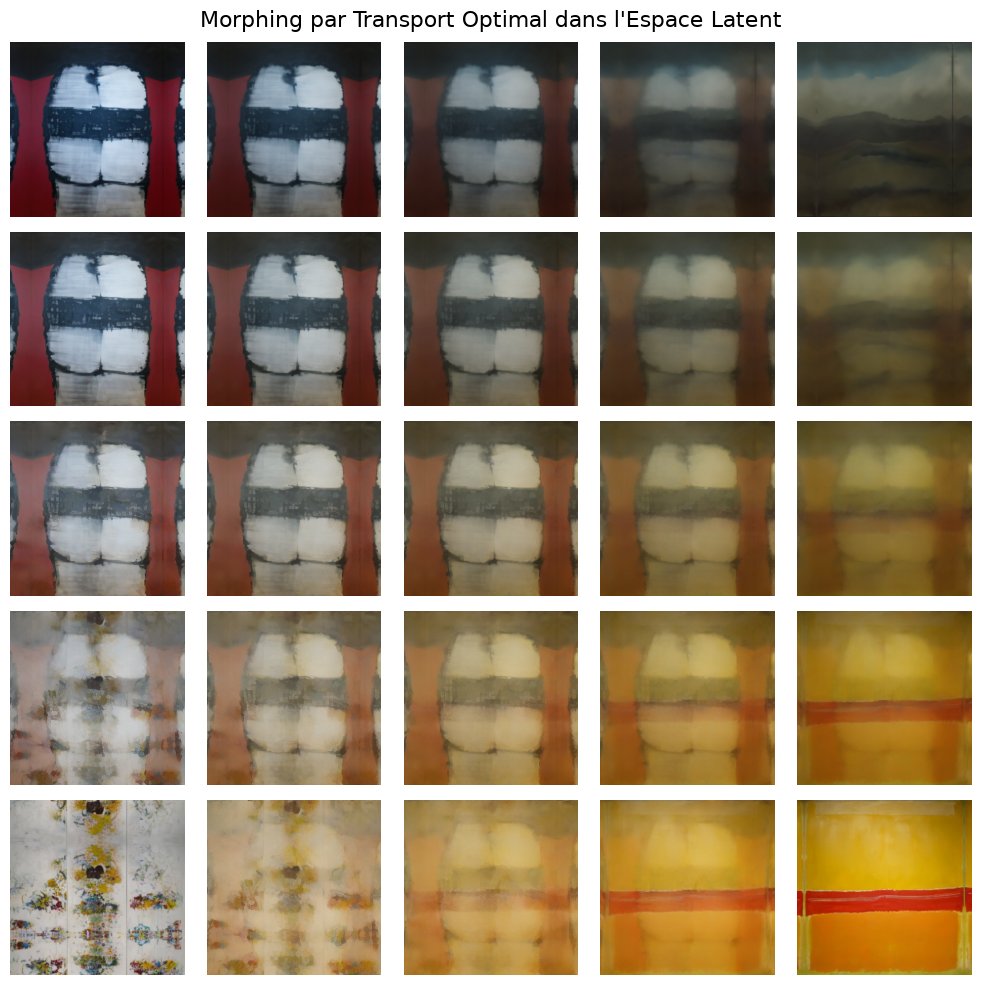

In [76]:
Z_clouds = [encode_painting(selected_img[k][1]) for k in range(4)]
names = [selected_img[k][0][:15] for k in range(4)]

alpha_weight = 0.0 # 0 = style pur, >10 = forte contrainte de composition
dist_matrix = np.zeros((4, 4))
Z1_mapped = [Z_clouds[0]] # Contiendra les versions de Z2, Z3, Z4 alignées sur Z1

for i in range(4):
    for j in range(i + 1, 4):
        dist, z_trans = compute_latent_ot(Z_clouds[i], Z_clouds[j], alpha=alpha_weight)
        dist_matrix[i, j] = dist
        dist_matrix[j, i] = dist
        if i == 0:
            Z1_mapped.append(z_trans)

# Affichage de la matrice de distance
fig_dist, ax_dist = plt.subplots(figsize=(6, 5))
cax = ax_dist.matshow(dist_matrix, cmap="magma")
fig_dist.colorbar(cax, label="Distance de Wasserstein Latente ($W_2$)")
ax_dist.set_xticks(range(4))
ax_dist.set_yticks(range(4))
ax_dist.set_xticklabels(names, rotation=45, ha="left")
ax_dist.set_yticklabels(names)
for i in range(4):
    for j in range(4):
        ax_dist.text(j, i, f"{dist_matrix[i, j]:.2f}", va="center", ha="center", 
                     color="white" if dist_matrix[i, j] < dist_matrix.max()/2 else "black")
plt.title("Distances Sémantiques entre les Tableaux")
plt.tight_layout()
plt.show()

# 5. Grille 5x5 : Morphing par Transport Optimal Latent
nb_images = 5
v1, v2, v3, v4 = np.eye(4)

fig, axes = plt.subplots(nb_images, nb_images, figsize=(10, 10))
plt.suptitle("Morphing par Transport Optimal dans l'Espace Latent", fontsize=16)

for i in range(nb_images):
    for j in range(nb_images):
        tx = float(i) / (nb_images - 1)
        ty = float(j) / (nb_images - 1)

        weights = (1 - ty) * ((1 - tx) * v1 + tx * v2) + ty * ((1 - tx) * v3 + tx * v4)

        # Astuce d'interpolation hybride :
        # Pour chaque tableau k, à mesure que son poids w_k approche de 1, on glisse 
        # de sa version "alignée sur le tableau 1" (Z1_mapped[k]) vers sa structure native (Z_clouds[k]).
        # Cela garantit une transition de texture par OT au centre, et les vrais tableaux aux 4 coins.
        z_interp = np.zeros_like(Z_clouds[0])
        for k in range(4):
            w_k = weights[k]
            z_k_effective = (1.0 - w_k) * Z1_mapped[k] + w_k * Z_clouds[k]
            z_interp += w_k * z_k_effective

        img_generated = decode_latent_cloud(z_interp)
        axes[i, j].imshow(img_generated)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

# Classification

/Users/arthurevain/Documents/Code/abstract_art_classification/.venv/lib/python3.14/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Encodage VAE: 100%|██████████| 32/32 [20:04<00:00, 37.65s/it]


Calcul des 499500 distances de Wasserstein sur tous les cœurs CPU...


Wasserstein OT: 100%|██████████| 999/999 [03:05<00:00,  5.40it/s]


Score de Silhouette global (Wasserstein) : 0.0549
Fichier 'classification_wasserstein_1000.csv' généré avec succès.
          Nom_Fichier     Artiste  Cluster_ID  Distance_Centroide  \
0       rothko_54.jpg      Rothko           1              5.1503   
1          hong_1.jpg        Hong           0              3.5972   
2     degottex_11.jpg    Degottex           4              3.7860   
3       michaux_4.jpg     Michaux           0              2.2593   
4  van_doesburg_1.jpg         Van           0              4.7425   
5    alechinsky_4.jpg  Alechinsky           0              3.5722   
6    kandinsky_22.jpg   Kandinsky           0              3.4359   
7      lipchitz_9.jpg    Lipchitz           2              3.2741   
8         asse_10.jpg        Asse           0              5.5727   
9     vasarely_14.jpg    Vasarely           0              4.2186   

   Score_Silhouette  
0            0.1798  
1            0.0291  
2            0.2788  
3            0.2106  
4           -0

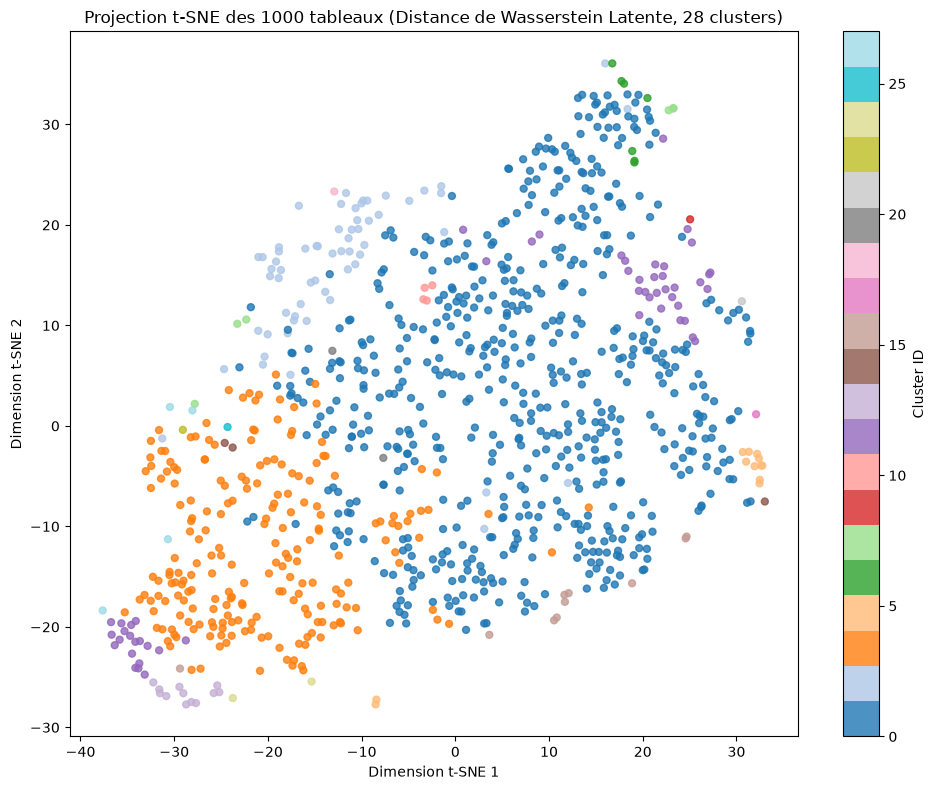

In [ ]:
nb_samples = min(1000, len(images))
sampled_images = random.sample(images, nb_samples)
filenames = [item[0] for item in sampled_images]

artists = [fn.split('_')[0].capitalize() for fn in filenames]

device = "cuda" if torch.cuda.is_available() else "cpu"
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device)
vae.eval()

GRID_SIZE = 12 # 12x12 = 144 patchs (accélère EMD d'un facteur x1000)

def encode_batch_pooled(img_list, batch_size=32):
    clouds = []
    for i in tqdm(range(0, len(img_list), batch_size), desc="Encodage VAE"):
        batch_imgs = []
        for _, img_array in img_list[i:i+batch_size]:
            img = np.array(img_array, dtype=np.float32) / 255.0
            if img.ndim == 2:
                img = np.stack([img]*3, axis=-1)
            batch_imgs.append(torch.from_numpy(img).permute(2, 0, 1))
        
        tensor = torch.stack(batch_imgs).to(device)
        tensor = F.interpolate(tensor, size=(304, 304), mode="bilinear", align_corners=False)
        tensor = (tensor * 2.0) - 1.0
        
        with torch.no_grad():
            z = vae.encode(tensor).latent_dist.mode() # (B, 4, 38, 38)
            # Réduction à une grille 12x12 pour préserver la topologie sans saturer le CPU
            z_pooled = F.adaptive_avg_pool2d(z, (GRID_SIZE, GRID_SIZE)) # (B, 4, 12, 12)
            
        z_np = z_pooled.permute(0, 2, 3, 1).reshape(-1, GRID_SIZE * GRID_SIZE, 4).cpu().numpy()
        clouds.extend(z_np)
    return np.array(clouds)

Z_all = encode_batch_pooled(sampled_images)

grid_y, grid_x = np.meshgrid(np.linspace(0, 1, GRID_SIZE), np.linspace(0, 1, GRID_SIZE), indexing='ij')
spatial_coords = np.stack([grid_x.ravel(), grid_y.ravel()], axis=1)
M_spatial = ot.dist(spatial_coords, spatial_coords, metric='sqeuclidean')

N_PATCHES = GRID_SIZE * GRID_SIZE
unif_weight = np.ones(N_PATCHES) / N_PATCHES
ALPHA = 5.0 # Poids de la composition spatiale vs style

def compute_row_distances(i, Z_all, M_spatial, alpha):
    """Calcule les distances entre l'image i et toutes les images j > i."""
    zA = Z_all[i]
    row_dists = np.zeros(len(Z_all) - (i + 1), dtype=np.float32)
    for idx, j in enumerate(range(i + 1, len(Z_all))):
        zB = Z_all[j]
        M_latent = ot.dist(zA, zB, metric='sqeuclidean')
        M_total = M_latent + alpha * M_spatial

        cost = ot.emd2(unif_weight, unif_weight, M_total)
        row_dists[idx] = np.sqrt(max(cost, 0.0))
    return i, row_dists

print(f"Calcul des {nb_samples * (nb_samples - 1) // 2} distances de Wasserstein sur tous les cœurs CPU...")
results = Parallel(n_jobs=-1, prefer="threads")(
    delayed(compute_row_distances)(i, Z_all, M_spatial, ALPHA) 
    for i in tqdm(range(nb_samples - 1), desc="Wasserstein OT")
)

# Assemblage de la matrice symétrique
dist_matrix = np.zeros((nb_samples, nb_samples), dtype=np.float32)
for i, row_dists in results:
    dist_matrix[i, i+1:] = row_dists
    dist_matrix[i+1:, i] = row_dists

N_CLUSTERS = 28

clustering = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    metric="precomputed",
    linkage="average" # "average" (UPGMA) ou "complete" fonctionnent avec une métrique non-euclidienne
)
labels = clustering.fit_predict(dist_matrix)

sil_samples = silhouette_samples(dist_matrix, labels, metric="precomputed")
global_sil = silhouette_score(dist_matrix, labels, metric="precomputed")
print(f"Score de Silhouette global (Wasserstein) : {global_sil:.4f}")

dist_to_centroid = np.zeros(nb_samples)
for c in range(N_CLUSTERS):
    idx_cluster = np.where(labels == c)[0]
    if len(idx_cluster) > 1:
        sub_dist = dist_matrix[np.ix_(idx_cluster, idx_cluster)]
        # Le médoïde est le tableau qui minimise la distance moyenne aux autres tableaux du cluster
        medoid_local_idx = np.argmin(sub_dist.mean(axis=1))
        medoid_global_idx = idx_cluster[medoid_local_idx]
        dist_to_centroid[idx_cluster] = dist_matrix[idx_cluster, medoid_global_idx]

df_out = pd.DataFrame({
    "Nom_Fichier": filenames,
    "Artiste": artists,
    "Cluster_ID": labels,
    "Distance_Centroide": np.round(dist_to_centroid, 4),
    "Score_Silhouette": np.round(sil_samples, 4)
})
df_out.to_csv("classification_wasserstein_1000.csv", index=False)
print("Fichier 'classification_wasserstein_1000.csv' généré avec succès.")
print(df_out.head(10))



tsne = TSNE(n_components=2, metric="precomputed", init="random", random_state=42, perplexity=30)
coords_2d = tsne.fit_transform(dist_matrix)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(coords_2d[:, 0], coords_2d[:, 1], c=labels, cmap="tab20", s=25, alpha=0.8)
plt.colorbar(scatter, label="Cluster ID")
plt.title(f"Projection t-SNE des 1000 tableaux (Distance de Wasserstein Latente, {N_CLUSTERS} clusters)")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.tight_layout()
plt.show()

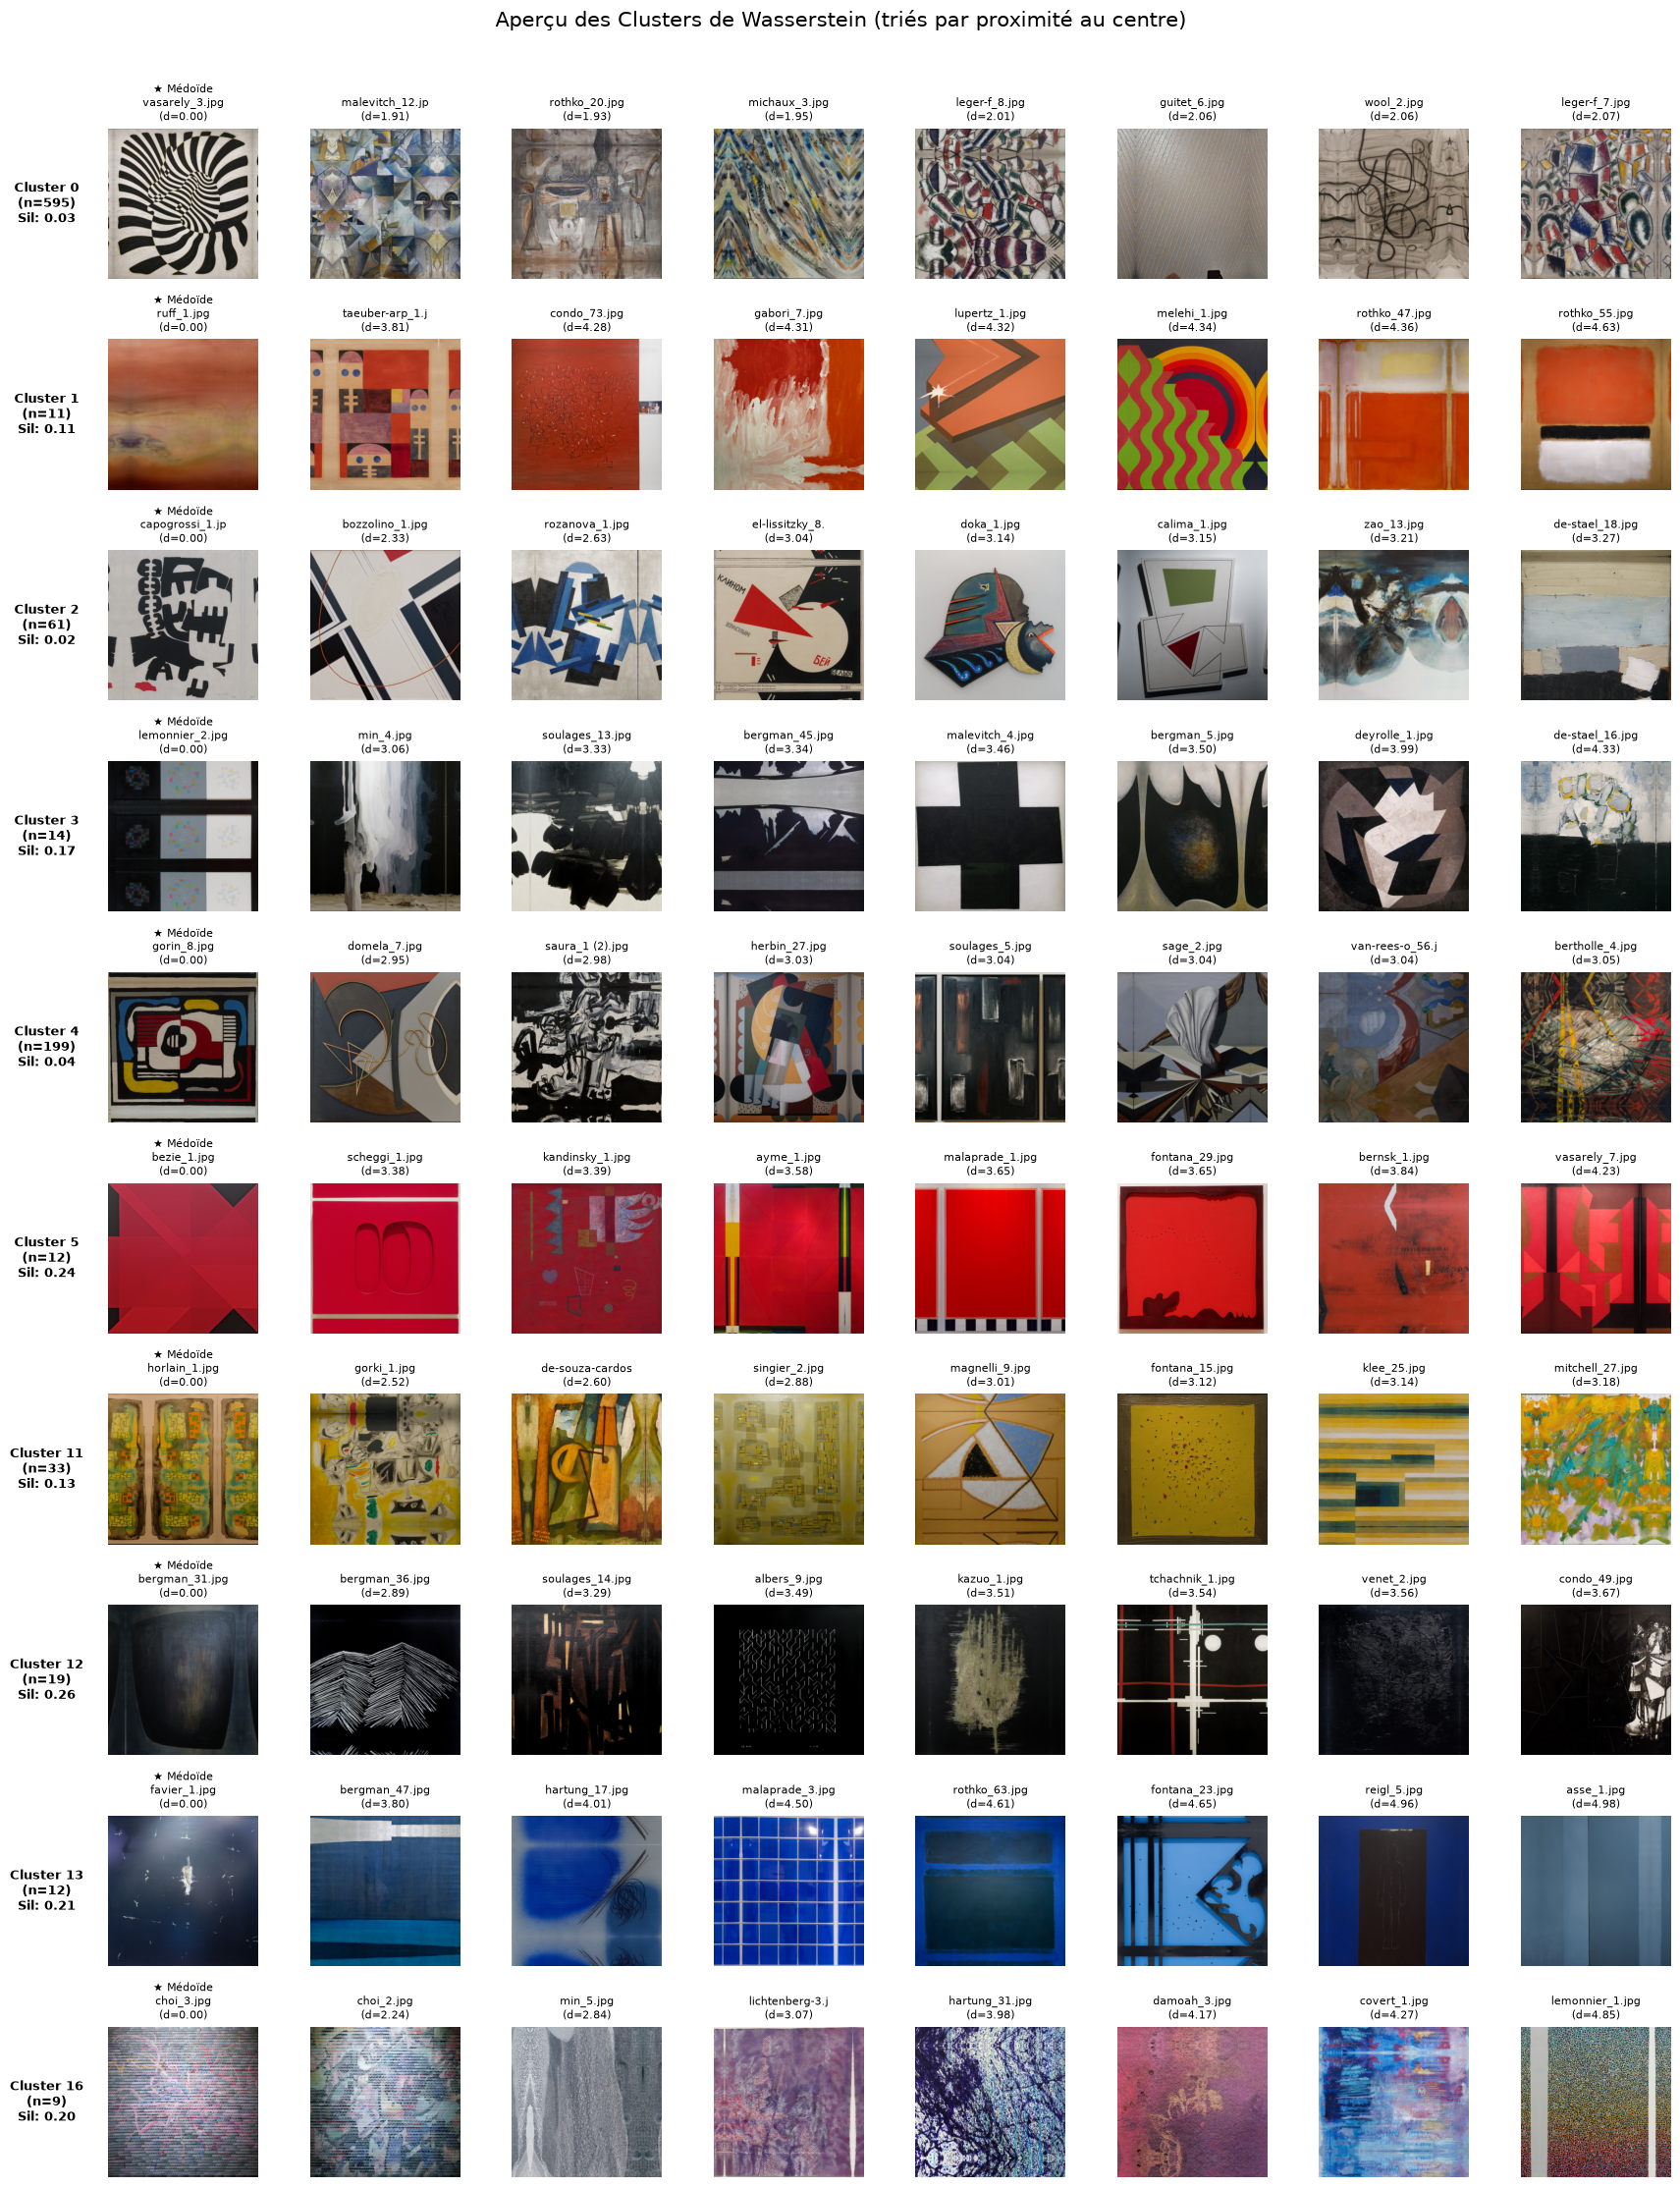

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Chargement du CSV et création d'un dictionnaire d'accès rapide aux images
df = pd.read_csv("classification_wasserstein_1000.csv")
img_dict = dict(images) # Convertit la liste [(filename, array), ...] en dictionnaire {filename: array}

def plot_clusters_overview(df, img_dict, samples_per_cluster=8, max_clusters=15):
    """
    Affiche une vue panoramique : 1 ligne = 1 cluster (trié par taille ou par ID).
    Les images sont triées de la plus centrale (médoïde) à la plus éloignée.
    """
    # Sélection des clusters les plus peuplés (ou les premiers par ID)
    top_clusters = df["Cluster_ID"].value_counts().head(max_clusters).index.tolist()
    top_clusters.sort()
    
    n_rows = len(top_clusters)
    fig, axes = plt.subplots(n_rows, samples_per_cluster, figsize=(samples_per_cluster * 2.2, n_rows * 2.2))
    
    if n_rows == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_idx, cluster_id in enumerate(top_clusters):
        # On trie par Distance_Centroide pour afficher le médoïde en premier (colonne 0)
        df_cluster = df[df["Cluster_ID"] == cluster_id].sort_values(by="Distance_Centroide", ascending=True)
        total_in_cluster = len(df_cluster)
        mean_sil = df_cluster["Score_Silhouette"].mean()
        
        selected_rows = df_cluster.head(samples_per_cluster)
        
        for col_idx in range(samples_per_cluster):
            ax = axes[row_idx, col_idx]
            
            if col_idx < len(selected_rows):
                row_data = selected_rows.iloc[col_idx]
                fname = row_data["Nom_Fichier"]
                dist = row_data["Distance_Centroide"]
                
                if fname in img_dict:
                    img = img_dict[fname]
                    display_img = img / 255.0 if img.max() > 1.0 else img
                    ax.imshow(display_img)
                
                # Titre au-dessus de chaque miniature
                prefix = "★ Médoïde\n" if col_idx == 0 else ""
                ax.set_title(f"{prefix}{fname[:15]}\n(d={dist:.2f})", fontsize=8)
            
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            
            # Étiquette du cluster à gauche de la première colonne
            if col_idx == 0:
                ax.set_ylabel(
                    f"Cluster {cluster_id}\n(n={total_in_cluster})\nSil: {mean_sil:.2f}", 
                    fontsize=9, fontweight="bold", rotation=0, labelpad=45, va="center"
                )

    plt.suptitle("Aperçu des Clusters de Wasserstein (triés par proximité au centre)", fontsize=15, y=1.01)
    plt.tight_layout()
    plt.show()

# Exemple : afficher les 10 clusters principaux avec 8 tableaux par cluster
plot_clusters_overview(df, img_dict, samples_per_cluster=8, max_clusters=10)

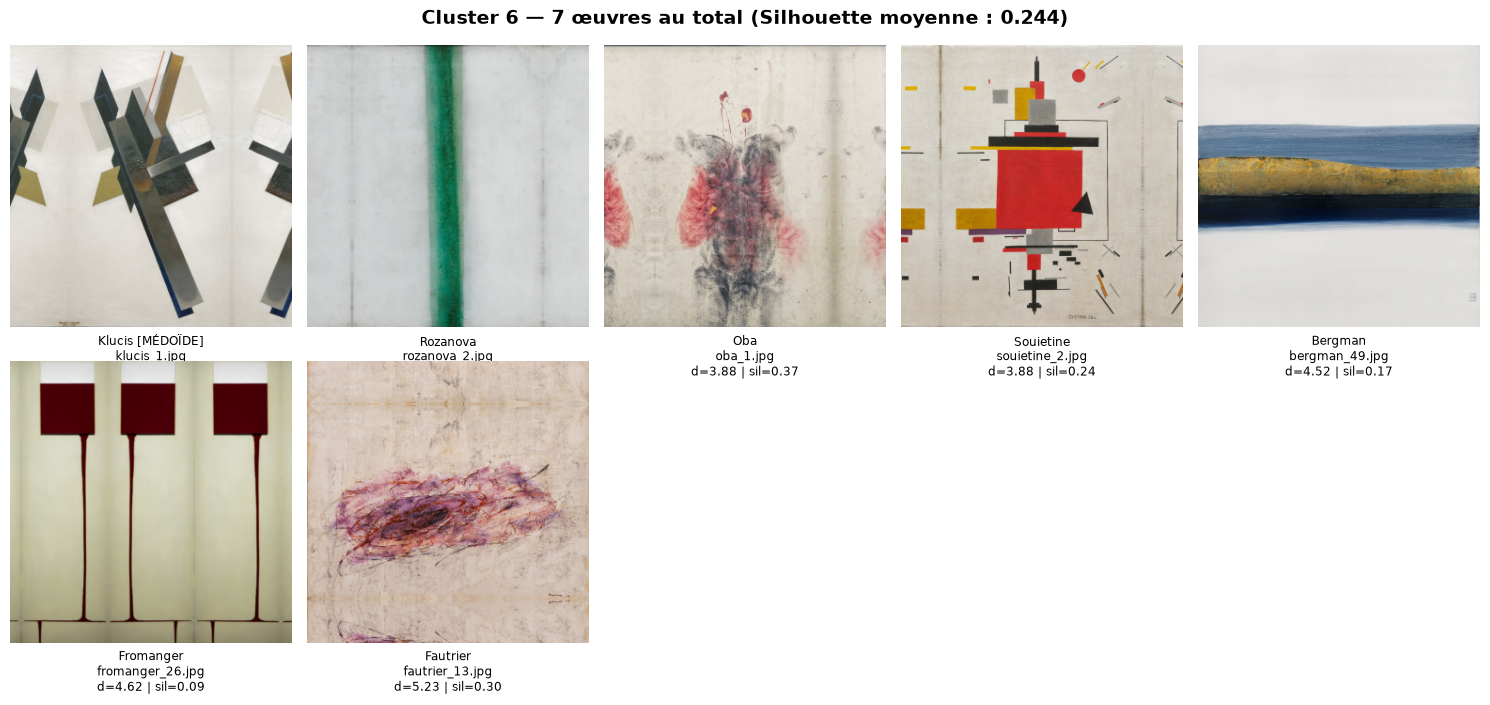

In [ ]:
def inspect_single_cluster(cluster_id, df, img_dict, max_images=25, cols=5):
    """Affiche une grille détaillée des œuvres appartenant à un cluster précis."""
    df_c = df[df["Cluster_ID"] == cluster_id].sort_values(by="Distance_Centroide", ascending=True)
    
    if df_c.empty:
        print(f"Le cluster {cluster_id} est vide ou n'existe pas.")
        return
        
    n_imgs = min(len(df_c), max_images)
    rows = math.ceil(n_imgs / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3.4))
    axes = np.array(axes).reshape(-1) # Aplatit la grille d'axes pour itérer facilement
    
    mean_sil = df_c["Score_Silhouette"].mean()
    plt.suptitle(
        f"Cluster {cluster_id} — {len(df_c)} œuvres au total (Silhouette moyenne : {mean_sil:.3f})", 
        fontsize=14, fontweight="bold"
    )
    
    for idx in range(len(axes)):
        ax = axes[idx]
        if idx < n_imgs:
            row = df_c.iloc[idx]
            fname = row["Nom_Fichier"]
            artist = row["Artiste"]
            dist = row["Distance_Centroide"]
            sil = row["Score_Silhouette"]
            
            if fname in img_dict:
                img = img_dict[fname]
                display_img = img / 255.0 if img.max() > 1.0 else img
                ax.imshow(display_img)
                
            role = " [MÉDOÏDE]" if idx == 0 else ""
            ax.set_title(
                f"{artist}{role}\n{fname}\nd={dist:.2f} | sil={sil:.2f}", 
                fontsize=8.5, y=-0.2
            )
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()


inspect_single_cluster(cluster_id=6, df=df, img_dict=img_dict, max_images=20, cols=5)